Dataset: Oxford-IIIT Pet (subset 10 kelas: 5 kucing + 5 anjing) | Backbone utama: ResNet-18 | Platform: Google Colab (GPU T4)

In [ ]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn", "pandas", "matplotlib"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'scikit-learn', 'pandas', 'matplotlib'], returncode=0)

In [ ]:
import os, random, time, json, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CFG = dict(
    batch_size=32,
    max_epochs=30,
    patience=5,
    weight_decay=1e-2,
    lr_scratch=1e-3,
    lr_head=1e-3,
    lr_backbone=1e-4,
    num_classes=10,
    seed=SEED,
)

OUT = Path("results"); OUT.mkdir(exist_ok=True)
print("torch", torch.__version__, "| device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU (sangat lambat, aktifkan GPU!)")

torch 2.11.0+cu130 | device: cuda | Tesla T4


In [ ]:
CAT_BREEDS = ["Abyssinian", "Bengal", "Persian", "Siamese", "Sphynx"]
DOG_BREEDS = ["Beagle", "Boxer", "Pug", "Shiba Inu", "Samoyed"]
SELECTED = CAT_BREEDS + DOG_BREEDS

raw_tv = datasets.OxfordIIITPet(root="data", split="trainval", target_types="category", download=True)
raw_te = datasets.OxfordIIITPet(root="data", split="test", target_types="category", download=True)

all_classes = raw_tv.classes
name_to_idx = {n: i for i, n in enumerate(all_classes)}
missing = [b for b in SELECTED if b not in name_to_idx]
assert not missing, f"Nama kelas tidak ditemukan: {missing}. Cek: {all_classes}"
old2new = {name_to_idx[n]: k for k, n in enumerate(SELECTED)}

paths, labels = [], []
for ds in (raw_tv, raw_te):
    for p, l in zip(ds._images, ds._labels):
        if l in old2new:
            paths.append(str(p)); labels.append(old2new[l])
labels = np.array(labels)

idx = np.arange(len(paths))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=labels[tmp_idx], random_state=SEED)

print(f"Total citra: {len(paths)} | train: {len(tr_idx)} | val: {len(va_idx)} | test: {len(te_idx)}")
print(pd.DataFrame({"kelas": SELECTED,
                    "train": np.bincount(labels[tr_idx], minlength=10),
                    "val": np.bincount(labels[va_idx], minlength=10),
                    "test": np.bincount(labels[te_idx], minlength=10)}))

100%|██████████| 792M/792M [00:56<00:00, 14.0MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 6.95MB/s]


Total citra: 1996 | train: 1397 | val: 299 | test: 300
        kelas  train  val  test
0  Abyssinian    139   29    30
1      Bengal    140   30    30
2     Persian    140   30    30
3     Siamese    139   30    30
4      Sphynx    140   30    30
5      Beagle    140   30    30
6       Boxer    139   30    30
7         Pug    140   30    30
8   Shiba Inu    140   30    30
9     Samoyed    140   30    30


In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tfm = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tfm = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class PetSubset(Dataset):
    def __init__(self, indices, transform):
        self.indices, self.transform = indices, transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        img = Image.open(paths[j]).convert("RGB")
        return self.transform(img), int(labels[j])

def _worker_init(worker_id):
    s = SEED + worker_id
    np.random.seed(s); random.seed(s)

def make_loader(indices, tfm, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(PetSubset(indices, tfm), batch_size=CFG["batch_size"], shuffle=shuffle,
                      num_workers=2, pin_memory=True, generator=g, worker_init_fn=_worker_init)

In [ ]:
def build_model(arch="resnet18", strategy="B2", pretrained=None):
    nc = CFG["num_classes"]
    use_pre = (strategy != "B1") if pretrained is None else pretrained

    if arch == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if use_pre else None)
        m.fc = nn.Linear(m.fc.in_features, nc)
        head, last = m.fc, [m.layer4]
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if use_pre else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, nc)
        head, last = m.classifier, [m.features[7], m.features[8]]
    elif arch == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if use_pre else None)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, nc)
        head, last = m.classifier, list(m.features[-3:])
    else:
        raise ValueError(arch)

    if strategy in ("B2", "B3"):
        for p in m.parameters():
            p.requires_grad = False
        for p in head.parameters():
            p.requires_grad = True
        if strategy == "B3":
            for blk in last:
                for p in blk.parameters():
                    p.requires_grad = True
    return m, head, last

def count_params(m):
    trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
    total = sum(p.numel() for p in m.parameters())
    return trainable, total

def make_param_groups(m, head, last, strategy):
    if strategy == "B1":
        return [{"params": list(m.parameters()), "lr": CFG["lr_scratch"]}], f"all={CFG['lr_scratch']:g}"
    if strategy == "B2":
        return [{"params": list(head.parameters()), "lr": CFG["lr_head"]}], f"head={CFG['lr_head']:g}"
    backbone = [p for blk in last for p in blk.parameters()]
    return ([{"params": backbone, "lr": CFG["lr_backbone"]},
             {"params": list(head.parameters()), "lr": CFG["lr_head"]}],
            f"last_blocks={CFG['lr_backbone']:g}; head={CFG['lr_head']:g}")

def set_train_mode(m):
    m.train()
    for mod in m.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm):
            ps = list(mod.parameters())
            if ps and not any(p.requires_grad for p in ps):
                mod.eval()

def run_epoch(model, loader, criterion, optimizer):
    set_train_mode(model)
    tot_loss = correct = n = 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        out = model(x); loss = criterion(out, y)
        optimizer.zero_grad(set_to_none=True)
        loss.backward(); optimizer.step()
        tot_loss += loss.item() * x.size(0)
        correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return tot_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    tot_loss = n = 0
    ys, ps, prob = [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        out = model(x)
        tot_loss += criterion(out, y).item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu()); prob.append(F.softmax(out, 1).cpu())
    y = torch.cat(ys).numpy(); p = torch.cat(ps).numpy(); pr = torch.cat(prob).numpy()
    return dict(loss=tot_loss / n, acc=accuracy_score(y, p), f1=f1_score(y, p, average="macro"),
                y=y, preds=p, probs=pr)

def _sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

RESULTS = {}

def save_logs():
    pd.DataFrame([r["summary"] for r in RESULTS.values()]).to_csv(OUT / "metrics_summary.csv", index=False)
    pd.concat([pd.DataFrame(r["history"]) for r in RESULTS.values()]).to_csv(OUT / "training_logs.csv", index=False)
    with open(OUT / "metrics_raw.json", "w") as f:
        json.dump({"config": CFG, "experiments": {k: {"summary": v["summary"], "history": v["history"]} for k, v in RESULTS.items()}}, f, indent=2)

def fit(name, arch, strategy, aug=True):
    set_seed(SEED)
    model, head, last = build_model(arch, strategy)
    model = model.to(DEVICE)
    trainable, total = count_params(model)
    print(f"\n=== {name} | {arch} | {strategy} | aug={aug} ===")
    print(f"Trainable Parameters: {trainable:,} / {total:,}")
    if arch == "resnet18" and strategy == "B2":
        assert trainable == 5130, "B2 pada ResNet-18 seharusnya 5.130 parameter trainable"

    groups, lr_desc = make_param_groups(model, head, last, strategy)
    optimizer = torch.optim.AdamW(groups, weight_decay=CFG["weight_decay"])
    criterion = nn.CrossEntropyLoss()

    train_loader = make_loader(tr_idx, train_tfm if aug else eval_tfm, shuffle=True)
    val_loader = make_loader(va_idx, eval_tfm, shuffle=False)

    best_val, best_epoch, best_state, wait, hist = float("inf"), 0, None, 0, []
    _sync(); t0 = time.time()
    for ep in range(1, CFG["max_epochs"] + 1):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vr = evaluate(model, val_loader, criterion)
        hist.append(dict(exp=name, epoch=ep, train_loss=tl, train_acc=ta,
                         val_loss=vr["loss"], val_acc=vr["acc"], val_macro_f1=vr["f1"]))
        print(f"ep {ep:02d} | train {tl:.4f}/{ta:.3f} | val {vr['loss']:.4f}/{vr['acc']:.3f}")
        if vr["loss"] < best_val - 1e-4:
            best_val, best_epoch, wait = vr["loss"], ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= CFG["patience"]:
                print(f"Early stopping pada epoch {ep} (best epoch = {best_epoch})"); break
    _sync(); duration = time.time() - t0

    model.load_state_dict(best_state)
    val_r = evaluate(model, val_loader, criterion)
    test_r = evaluate(model, make_loader(te_idx, eval_tfm, False), criterion)
    train_clean = evaluate(model, make_loader(tr_idx, eval_tfm, False), criterion)  # tanpa augmentasi

    torch.save({"state_dict": best_state, "arch": arch, "strategy": strategy}, OUT / f"ckpt_{name}.pt")

    summary = dict(
        exp=name, arch=arch, strategy=strategy, augmentation=bool(aug),
        trainable_params=int(trainable), total_params=int(total), lr_groups=lr_desc,
        epochs_run=len(hist), best_epoch=int(best_epoch), train_time_s=round(float(duration), 2),
        train_acc_clean=float(train_clean["acc"]), val_acc=float(val_r["acc"]), val_loss=float(val_r["loss"]),
        val_macro_f1=float(val_r["f1"]), test_acc=float(test_r["acc"]), test_macro_f1=float(test_r["f1"]),
        gap_train_val=float(train_clean["acc"] - val_r["acc"]), seed=SEED,
    )
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in summary.items()})
    RESULTS[name] = dict(summary=summary, history=hist, test=test_r)
    save_logs()
    return RESULTS[name]

In [ ]:
fit("B1_scratch", "resnet18", "B1", aug=True)
fit("B2_feature_extraction", "resnet18", "B2", aug=True)
fit("B3_progressive_ft", "resnet18", "B3", aug=True)


=== B1_scratch | resnet18 | B1 | aug=True ===
Trainable Parameters: 11,181,642 / 11,181,642
ep 01 | train 2.3773/0.162 | val 2.5561/0.174
ep 02 | train 2.0868/0.241 | val 2.1382/0.211
ep 03 | train 1.9559/0.312 | val 2.0189/0.298
ep 04 | train 1.8949/0.339 | val 2.3851/0.201
ep 05 | train 1.7862/0.353 | val 2.3151/0.308
ep 06 | train 1.7399/0.377 | val 2.2308/0.261
ep 07 | train 1.7158/0.382 | val 2.4783/0.278
ep 08 | train 1.6387/0.413 | val 1.7288/0.391
ep 09 | train 1.5335/0.460 | val 1.6635/0.448
ep 10 | train 1.5171/0.476 | val 1.5284/0.498
ep 11 | train 1.3900/0.512 | val 1.8357/0.391
ep 12 | train 1.3636/0.545 | val 2.1210/0.385
ep 13 | train 1.2854/0.567 | val 1.5294/0.482
ep 14 | train 1.2285/0.571 | val 1.9340/0.448
ep 15 | train 1.1308/0.618 | val 1.5082/0.518
ep 16 | train 1.0641/0.634 | val 1.6007/0.522
ep 17 | train 1.0286/0.635 | val 1.8817/0.458
ep 18 | train 1.0150/0.639 | val 1.5100/0.518
ep 19 | train 0.8599/0.703 | val 1.3913/0.575
ep 20 | train 0.8793/0.686 | val 

100%|██████████| 44.7M/44.7M [00:00<00:00, 247MB/s]



=== B2_feature_extraction | resnet18 | B2 | aug=True ===
Trainable Parameters: 5,130 / 11,181,642
ep 01 | train 1.1539/0.722 | val 0.4539/0.933
ep 02 | train 0.3641/0.940 | val 0.2479/0.967
ep 03 | train 0.2531/0.950 | val 0.2049/0.953
ep 04 | train 0.1869/0.963 | val 0.1611/0.980
ep 05 | train 0.1674/0.966 | val 0.1452/0.977
ep 06 | train 0.1452/0.968 | val 0.1229/0.980
ep 07 | train 0.1318/0.967 | val 0.1185/0.983
ep 08 | train 0.1267/0.969 | val 0.1181/0.977
ep 09 | train 0.1092/0.972 | val 0.1056/0.977
ep 10 | train 0.1033/0.974 | val 0.1089/0.973
ep 11 | train 0.0979/0.979 | val 0.0974/0.977
ep 12 | train 0.0919/0.982 | val 0.1144/0.967
ep 13 | train 0.0864/0.979 | val 0.0909/0.980
ep 14 | train 0.0818/0.979 | val 0.0985/0.973
ep 15 | train 0.0737/0.984 | val 0.0800/0.980
ep 16 | train 0.0688/0.989 | val 0.0983/0.977
ep 17 | train 0.0645/0.986 | val 0.0831/0.980
ep 18 | train 0.0620/0.987 | val 0.0905/0.980
ep 19 | train 0.0618/0.987 | val 0.0806/0.977
ep 20 | train 0.0571/0.991 

{'summary': {'exp': 'B3_progressive_ft',
  'arch': 'resnet18',
  'strategy': 'B3',
  'augmentation': True,
  'trainable_params': 8398858,
  'total_params': 11181642,
  'lr_groups': 'last_blocks=0.0001; head=0.001',
  'epochs_run': 11,
  'best_epoch': 6,
  'train_time_s': 80.19,
  'train_acc_clean': 0.9964209019327129,
  'val_acc': 0.9899665551839465,
  'val_loss': 0.06937948965551612,
  'val_macro_f1': 0.9898841312880654,
  'test_acc': 0.97,
  'test_macro_f1': 0.9699238327480273,
  'gap_train_val': 0.0064543467487664374,
  'seed': 42},
 'history': [{'exp': 'B3_progressive_ft',
   'epoch': 1,
   'train_loss': 0.6197167820135183,
   'train_acc': 0.8468146027201146,
   'val_loss': 0.11910180085927348,
   'val_acc': 0.9632107023411371,
   'val_macro_f1': 0.9632419653290947},
  {'exp': 'B3_progressive_ft',
   'epoch': 2,
   'train_loss': 0.11930434787665936,
   'train_acc': 0.9735146743020758,
   'val_loss': 0.08262222028496273,
   'val_acc': 0.9832775919732442,
   'val_macro_f1': 0.9832694

In [ ]:
fit("B4_B3_noaug", "resnet18", "B3", aug=False)
fit("B4_B3_aug", "resnet18", "B3", aug=True)


=== B4_B3_noaug | resnet18 | B3 | aug=False ===
Trainable Parameters: 8,398,858 / 11,181,642
ep 01 | train 0.5310/0.880 | val 0.1133/0.960
ep 02 | train 0.0515/0.993 | val 0.0885/0.970
ep 03 | train 0.0154/1.000 | val 0.0869/0.980
ep 04 | train 0.0118/0.999 | val 0.0778/0.977
ep 05 | train 0.0052/1.000 | val 0.0780/0.977
ep 06 | train 0.0042/1.000 | val 0.0806/0.977
ep 07 | train 0.0032/1.000 | val 0.0783/0.980
ep 08 | train 0.0030/1.000 | val 0.0822/0.977
ep 09 | train 0.0021/1.000 | val 0.0805/0.980
Early stopping pada epoch 9 (best epoch = 4)
{'exp': 'B4_B3_noaug', 'arch': 'resnet18', 'strategy': 'B3', 'augmentation': False, 'trainable_params': 8398858, 'total_params': 11181642, 'lr_groups': 'last_blocks=0.0001; head=0.001', 'epochs_run': 9, 'best_epoch': 4, 'train_time_s': 45.35, 'train_acc_clean': 1.0, 'val_acc': 0.9766, 'val_loss': 0.0778, 'val_macro_f1': 0.9765, 'test_acc': 0.9733, 'test_macro_f1': 0.9732, 'gap_train_val': 0.0234, 'seed': 42}

=== B4_B3_aug | resnet18 | B3 | au

{'summary': {'exp': 'B4_B3_aug',
  'arch': 'resnet18',
  'strategy': 'B3',
  'augmentation': True,
  'trainable_params': 8398858,
  'total_params': 11181642,
  'lr_groups': 'last_blocks=0.0001; head=0.001',
  'epochs_run': 11,
  'best_epoch': 6,
  'train_time_s': 80.53,
  'train_acc_clean': 0.9964209019327129,
  'val_acc': 0.9899665551839465,
  'val_loss': 0.06937948965551612,
  'val_macro_f1': 0.9898841312880654,
  'test_acc': 0.97,
  'test_macro_f1': 0.9699238327480273,
  'gap_train_val': 0.0064543467487664374,
  'seed': 42},
 'history': [{'exp': 'B4_B3_aug',
   'epoch': 1,
   'train_loss': 0.6197167820135183,
   'train_acc': 0.8468146027201146,
   'val_loss': 0.11910180085927348,
   'val_acc': 0.9632107023411371,
   'val_macro_f1': 0.9632419653290947},
  {'exp': 'B4_B3_aug',
   'epoch': 2,
   'train_loss': 0.11930434787665936,
   'train_acc': 0.9735146743020758,
   'val_loss': 0.08262222028496273,
   'val_acc': 0.9832775919732442,
   'val_macro_f1': 0.9832694205111769},
  {'exp': 'B

In [ ]:
best_strategy = max(["B2_feature_extraction", "B3_progressive_ft"], key=lambda k: RESULTS[k]["summary"]["val_acc"])
best_strategy = "B2" if best_strategy.startswith("B2") else "B3"
print("Strategi terbaik (val acc):", best_strategy)
fit("B5_efficientnet_b0", "efficientnet_b0", best_strategy, aug=True)
fit("B5_mobilenet_v3_small", "mobilenet_v3_small", best_strategy, aug=True)

Strategi terbaik (val acc): B3
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 230MB/s]


=== B5_efficientnet_b0 | efficientnet_b0 | B3 | aug=True ===
Trainable Parameters: 1,142,202 / 4,020,358


ep 01 | train 0.9482/0.804 | val 0.1307/0.990
ep 02 | train 0.1678/0.970 | val 0.0637/0.990
ep 03 | train 0.1064/0.977 | val 0.0485/0.997
ep 04 | train 0.0801/0.982 | val 0.0414/0.990
ep 05 | train 0.0562/0.988 | val 0.0359/0.993
ep 06 | train 0.0499/0.986 | val 0.0361/0.993
ep 07 | train 0.0461/0.989 | val 0.0341/0.990
ep 08 | train 0.0390/0.990 | val 0.0327/0.993
ep 09 | train 0.0369/0.991 | val 0.0344/0.993
ep 10 | train 0.0254/0.996 | val 0.0361/0.990
ep 11 | train 0.0280/0.992 | val 0.0494/0.987
ep 12 | train 0.0198/0.994 | val 0.0370/0.990
ep 13 | train 0.0177/0.997 | val 0.0359/0.993
Early stopping pada epoch 13 (best epoch = 8)
{'exp': 'B5_efficientnet_b0', 'arch': 'efficientnet_b0', 'strategy': 'B3', 'augmentation': True, 'trainable_params': 1142202, 'total_params': 4020358, 'lr_groups': 'last_blocks=0.0001; head=0.001', 'epochs_run': 13, 'best_epoch': 8, 'train_time_s': 95.04, 'train_acc_clean': 0.9993, 'val_acc': 0.9933, 'val_loss': 0.0327, 'val_macro_f1': 0.9932, 'test_acc'

100%|██████████| 9.83M/9.83M [00:00<00:00, 229MB/s]


=== B5_mobilenet_v3_small | mobilenet_v3_small | B3 | aug=True ===
Trainable Parameters: 1,245,738 / 1,528,106


ep 01 | train 0.7886/0.766 | val 0.1761/0.936
ep 02 | train 0.2286/0.927 | val 0.1837/0.933
ep 03 | train 0.1337/0.956 | val 0.1847/0.923
ep 04 | train 0.1027/0.967 | val 0.1738/0.920
ep 05 | train 0.0644/0.983 | val 0.1604/0.933
ep 06 | train 0.0501/0.987 | val 0.2397/0.916
ep 07 | train 0.0540/0.979 | val 0.1723/0.943
ep 08 | train 0.0377/0.986 | val 0.1985/0.930
ep 09 | train 0.0335/0.991 | val 0.1714/0.940
ep 10 | train 0.0311/0.990 | val 0.1882/0.930
Early stopping pada epoch 10 (best epoch = 5)
{'exp': 'B5_mobilenet_v3_small', 'arch': 'mobilenet_v3_small', 'strategy': 'B3', 'augmentation': True, 'trainable_params': 1245738, 'total_params': 1528106, 'lr_groups': 'last_blocks=0.0001; head=0.001', 'epochs_run': 10, 'best_epoch': 5, 'train_time_s': 71.9, 'train_acc_clean': 0.9936, 'val_acc': 0.9331, 'val_loss': 0.1604, 'val_macro_f1': 0.933, 'test_acc': 0.9667, 'test_macro_f1': 0.9669, 'gap_train_val': 0.0604, 'seed': 42}


{'summary': {'exp': 'B5_mobilenet_v3_small',
  'arch': 'mobilenet_v3_small',
  'strategy': 'B3',
  'augmentation': True,
  'trainable_params': 1245738,
  'total_params': 1528106,
  'lr_groups': 'last_blocks=0.0001; head=0.001',
  'epochs_run': 10,
  'best_epoch': 5,
  'train_time_s': 71.9,
  'train_acc_clean': 0.9935576234788833,
  'val_acc': 0.9331103678929766,
  'val_loss': 0.1603854104415529,
  'val_macro_f1': 0.9330475034797013,
  'test_acc': 0.9666666666666667,
  'test_macro_f1': 0.9668762529615454,
  'gap_train_val': 0.06044725558590669,
  'seed': 42},
 'history': [{'exp': 'B5_mobilenet_v3_small',
   'epoch': 1,
   'train_loss': 0.7886157563501541,
   'train_acc': 0.7659269863994274,
   'val_loss': 0.1760723413432322,
   'val_acc': 0.9364548494983278,
   'val_macro_f1': 0.93613761340685},
  {'exp': 'B5_mobilenet_v3_small',
   'epoch': 2,
   'train_loss': 0.22859784734616045,
   'train_acc': 0.9269863994273443,
   'val_loss': 0.18374735396043912,
   'val_acc': 0.9331103678929766,


,exp,arch,strategy,augmentation,trainable_params,lr_groups,best_epoch,epochs_run,train_time_s,train_acc_clean,val_acc,test_macro_f1,gap_train_val
0,B1_scratch,resnet18,B1,True,11181642,all=0.001,23,28,213.60,0.725125,0.652174,0.654795,0.072951
1,B2_feature_extraction,resnet18,B2,True,5130,head=0.001,15,20,147.75,0.992842,0.979933,0.966818,0.012909
2,B3_progressive_ft,resnet18,B3,True,8398858,last_blocks=0.0001; head=0.001,6,11,80.19,0.996421,0.989967,0.969924,0.006454
3,B4_B3_noaug,resnet18,B3,False,8398858,last_blocks=0.0001; head=0.001,4,9,45.35,1.000000,0.976589,0.973247,0.023411
4,B4_B3_aug,resnet18,B3,True,8398858,last_blocks=0.0001; head=0.001,6,11,80.53,0.996421,0.989967,0.969924,0.006454
5,B5_efficientnet_b0,efficientnet_b0,B3,True,1142202,last_blocks=0.0001; head=0.001,8,13,95.04,0.999284,0.993311,0.980100,0.005973
6,B5_mobilenet_v3_small,mobilenet_v3_small,B3,True,1245738,last_blocks=0.0001; head=0.001,5,10,71.90,0.993558,0.933110,0.966876,0.060447


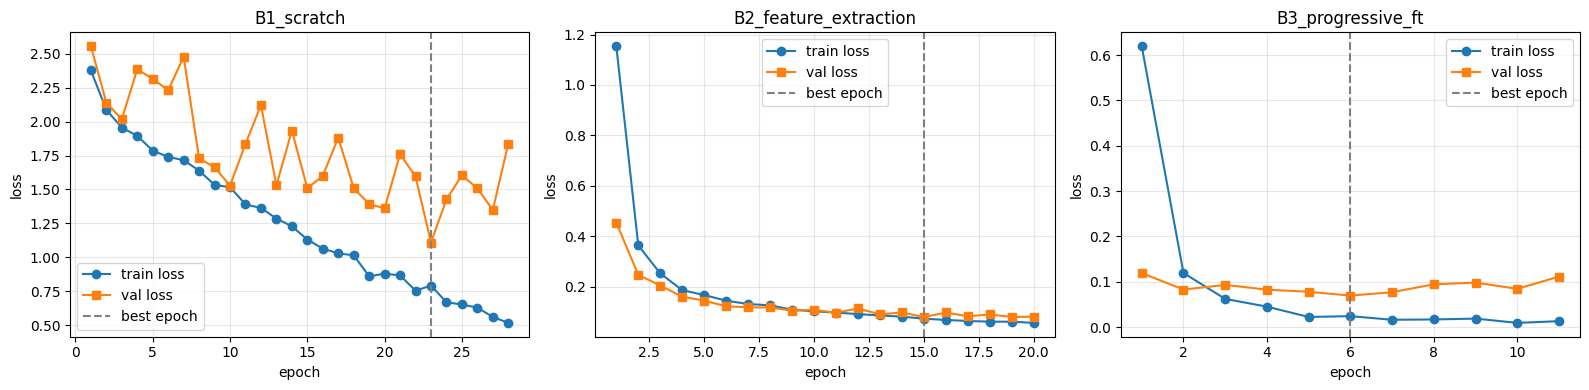

,exp,train_acc_clean,val_acc,gap_train_val,test_macro_f1
3,B4_B3_noaug,1.000000,0.976589,0.023411,0.973247
4,B4_B3_aug,0.996421,0.989967,0.006454,0.969924


In [ ]:
summary = pd.DataFrame([r["summary"] for r in RESULTS.values()])
cols = ["exp", "arch", "strategy", "augmentation", "trainable_params", "lr_groups", "best_epoch", "epochs_run",
        "train_time_s", "train_acc_clean", "val_acc", "test_macro_f1", "gap_train_val"]
display(summary[cols])

def df_to_md(df, floatfmt="{:.4f}"):
    cs = list(df.columns)
    lines = ["| " + " | ".join(cs) + " |", "|" + "|".join(["---"] * len(cs)) + "|"]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(floatfmt.format(r[c]) if isinstance(r[c], float) else str(r[c]) for c in cs) + " |")
    return "\n".join(lines)

(OUT / "consolidated_table.md").write_text(df_to_md(summary[cols]))

hist_df = pd.concat([pd.DataFrame(r["history"]) for r in RESULTS.values()])
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, name in zip(axes, ["B1_scratch", "B2_feature_extraction", "B3_progressive_ft"]):
    h = hist_df[hist_df.exp == name]
    ax.plot(h.epoch, h.train_loss, marker="o", label="train loss")
    ax.plot(h.epoch, h.val_loss, marker="s", label="val loss")
    ax.axvline(RESULTS[name]["summary"]["best_epoch"], ls="--", c="gray", label="best epoch")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / "fig_loss_curves_B1_B2_B3.png", dpi=150); plt.show()

# Ringkasan B4: celah train-val
b4 = summary[summary.exp.str.startswith("B4")][["exp", "train_acc_clean", "val_acc", "gap_train_val", "test_macro_f1"]]
display(b4)

Model terbaik: B5_efficientnet_b0 | test macro-F1: 0.9801
              precision    recall  f1-score   support

  Abyssinian      0.906     0.967     0.935        30
      Bengal      0.966     0.933     0.949        30
     Persian      1.000     1.000     1.000        30
     Siamese      1.000     0.967     0.983        30
      Sphynx      1.000     1.000     1.000        30
      Beagle      0.968     1.000     0.984        30
       Boxer      0.968     1.000     0.984        30
         Pug      1.000     0.967     0.983        30
   Shiba Inu      1.000     0.967     0.983        30
     Samoyed      1.000     1.000     1.000        30

    accuracy                          0.980       300
   macro avg      0.981     0.980     0.980       300
weighted avg      0.981     0.980     0.980       300



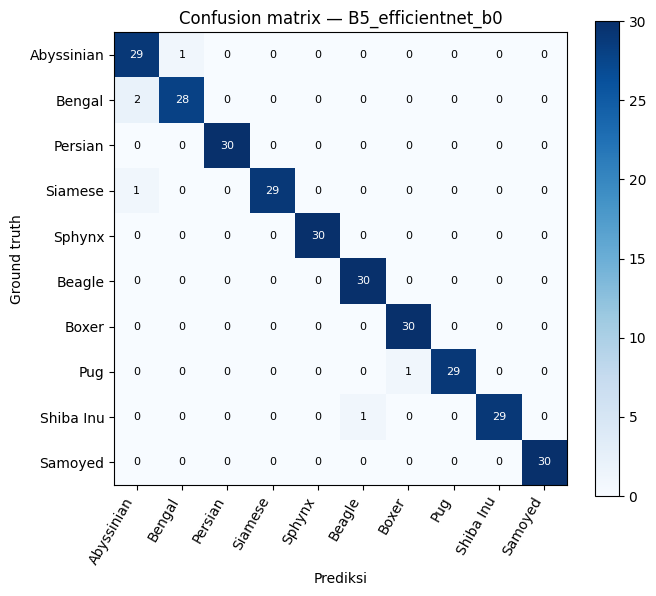

Jumlah salah prediksi di test: 6 dari 300


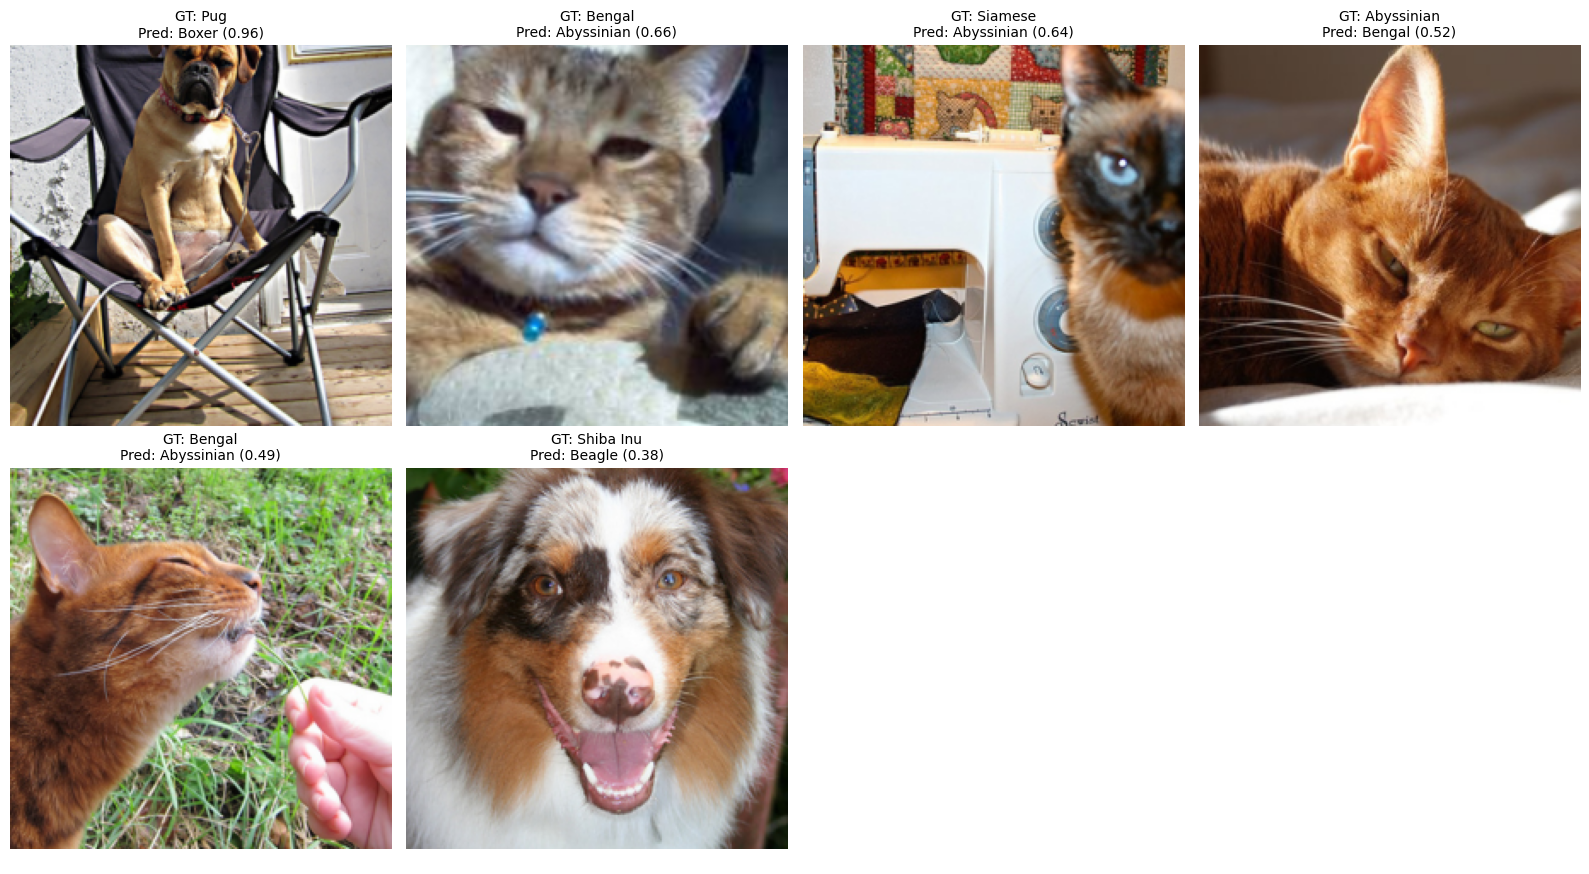

,file,ground_truth,prediction,confidence
0,data/oxford-iiit-pet/images/pug_74.jpg,Pug,Boxer,0.964763
1,data/oxford-iiit-pet/images/Bengal_143.jpg,Bengal,Abyssinian,0.657882
2,data/oxford-iiit-pet/images/Siamese_150.jpg,Siamese,Abyssinian,0.641375
3,data/oxford-iiit-pet/images/Abyssinian_150.jpg,Abyssinian,Bengal,0.520651
4,data/oxford-iiit-pet/images/Bengal_34.jpg,Bengal,Abyssinian,0.489693
5,data/oxford-iiit-pet/images/shiba_inu_156.jpg,Shiba Inu,Beagle,0.379511


In [ ]:
cands = {k: v for k, v in RESULTS.items() if not k.startswith("B4")}
best_name = max(cands, key=lambda k: cands[k]["summary"]["val_acc"])
print("Model terbaik:", best_name, "| test macro-F1:", round(cands[best_name]["summary"]["test_macro_f1"], 4))

tr = RESULTS[best_name]["test"]
print(classification_report(tr["y"], tr["preds"], target_names=SELECTED, digits=3))

cm = confusion_matrix(tr["y"], tr["preds"])
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im)
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(SELECTED, rotation=60, ha="right"); ax.set_yticklabels(SELECTED)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
ax.set_xlabel("Prediksi"); ax.set_ylabel("Ground truth"); ax.set_title(f"Confusion matrix — {best_name}")
plt.tight_layout(); plt.savefig(OUT / "fig_confusion_matrix.png", dpi=150); plt.show()

conf = tr["probs"][np.arange(len(tr["y"])), tr["preds"]]
wrong = np.where(tr["preds"] != tr["y"])[0]
order = wrong[np.argsort(-conf[wrong])]
show = order[:8]
print(f"Jumlah salah prediksi di test: {len(wrong)} dari {len(tr['y'])}")

disp_tfm = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])
fail_rows = []
if len(show):
    ncol = 4; nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 4.4 * nrow)); axes = np.array(axes).reshape(-1)
    for ax in axes: ax.axis("off")
    for ax, i in zip(axes, show):
        pth = paths[te_idx[i]]
        ax.imshow(disp_tfm(Image.open(pth).convert("RGB")))
        gt, pr = SELECTED[tr["y"][i]], SELECTED[tr["preds"][i]]
        ax.set_title(f"GT: {gt}\nPred: {pr} ({conf[i]:.2f})", fontsize=10)
        fail_rows.append(dict(file=pth, ground_truth=gt, prediction=pr, confidence=float(conf[i])))
    plt.tight_layout(); plt.savefig(OUT / "fig_failure_analysis.png", dpi=150); plt.show()
    pd.DataFrame(fail_rows).to_csv(OUT / "failure_samples.csv", index=False)
    display(pd.DataFrame(fail_rows))

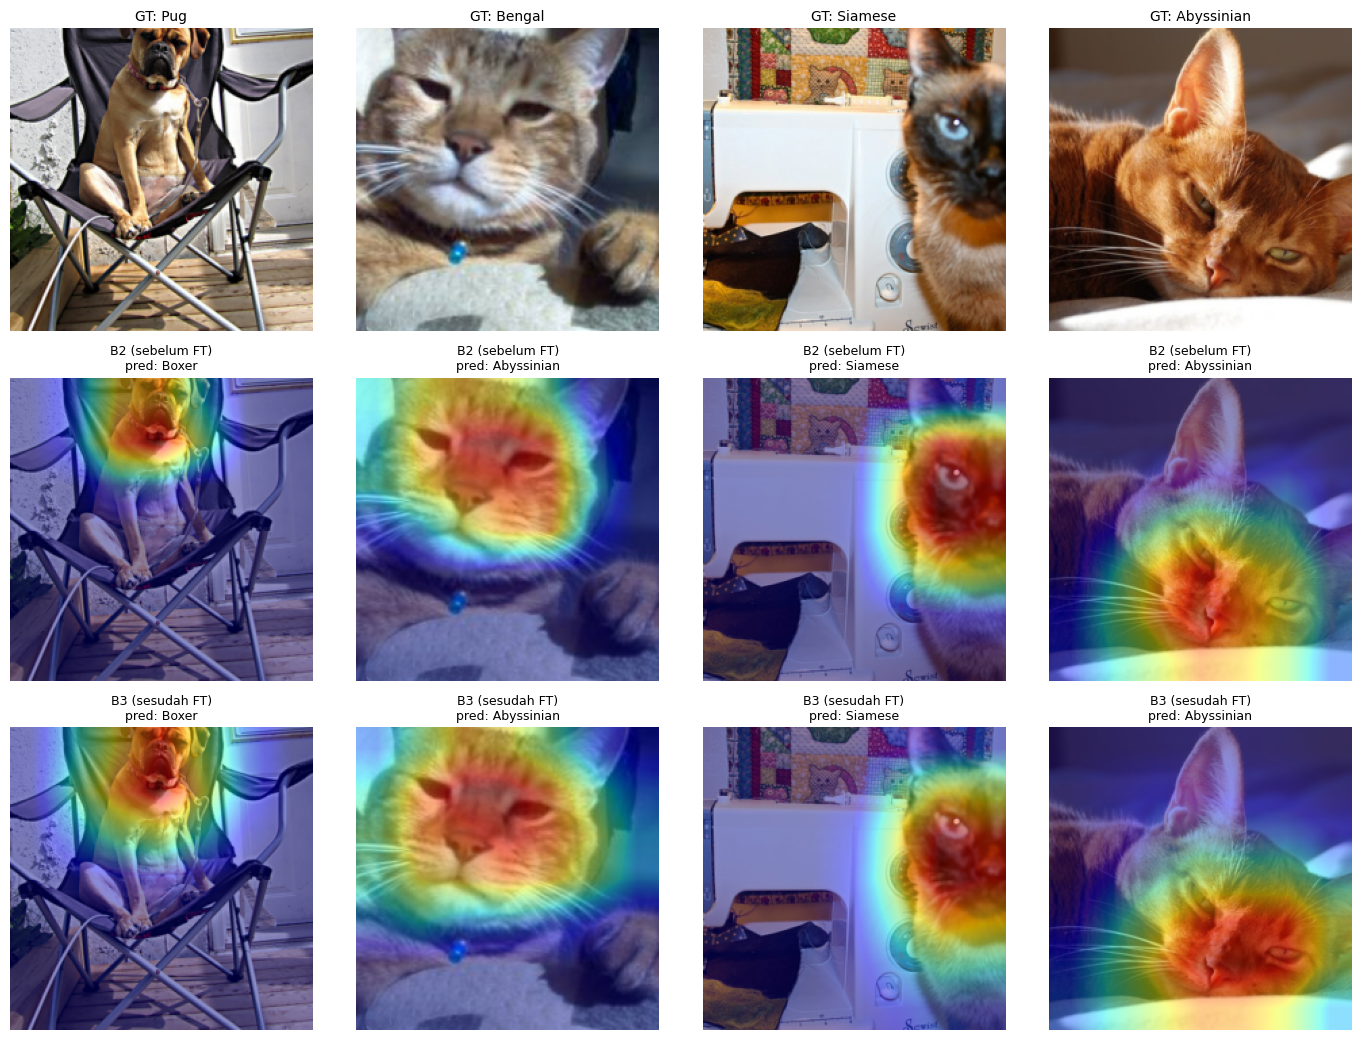

In [ ]:
def load_model(name):
    ck = torch.load(OUT / f"ckpt_{name}.pt", map_location=DEVICE)
    m, _, _ = build_model(ck["arch"], ck["strategy"], pretrained=False)
    m.load_state_dict(ck["state_dict"])
    return m.to(DEVICE).eval()

def gradcam(model, x, target):
    model.eval()
    store = {}
    h = model.layer4.register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
    x = x.clone().requires_grad_(True)
    out = model(x)
    grad = torch.autograd.grad(out[0, target], store["a"])[0]
    h.remove()
    w = grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.detach().cpu().numpy()

m_before, m_after = load_model("B2_feature_extraction"), load_model("B3_progressive_ft")

rng = np.random.RandomState(SEED)
sel = list(show[:4])
extra = [i for i in rng.permutation(len(te_idx)) if i not in sel]
sel = (sel + extra)[:4]

fig, axes = plt.subplots(3, 4, figsize=(14, 10.5))
for c, i in enumerate(sel):
    img = Image.open(paths[te_idx[i]]).convert("RGB")
    x = eval_tfm(img).unsqueeze(0).to(DEVICE)
    y = int(labels[te_idx[i]]); base = disp_tfm(img)
    axes[0, c].imshow(base); axes[0, c].set_title(f"GT: {SELECTED[y]}", fontsize=10)
    for r, (mdl, tag) in enumerate([(m_before, "B2 (sebelum FT)"), (m_after, "B3 (sesudah FT)")], start=1):
        cam = gradcam(mdl, x, y)
        pred = mdl(x).argmax(1).item()
        axes[r, c].imshow(base); axes[r, c].imshow(cam, cmap="jet", alpha=0.45)
        axes[r, c].set_title(f"{tag}\npred: {SELECTED[pred]}", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "fig_gradcam_B2_vs_B3.png", dpi=150); plt.show()

In [ ]:
save_logs()
print(sorted(p.name for p in OUT.iterdir()))

['ckpt_B1_scratch.pt', 'ckpt_B2_feature_extraction.pt', 'ckpt_B3_progressive_ft.pt', 'ckpt_B4_B3_aug.pt', 'ckpt_B4_B3_noaug.pt', 'ckpt_B5_efficientnet_b0.pt', 'ckpt_B5_mobilenet_v3_small.pt', 'consolidated_table.md', 'failure_samples.csv', 'fig_confusion_matrix.png', 'fig_failure_analysis.png', 'fig_gradcam_B2_vs_B3.png', 'fig_loss_curves_B1_B2_B3.png', 'metrics_raw.json', 'metrics_summary.csv', 'training_logs.csv']


In [ ]:
import zipfile, pathlib
with zipfile.ZipFile("results_ringan.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for p in pathlib.Path("results").iterdir():
        if p.suffix != ".pt":
            z.write(p, p.name)
print("Selesai. Unduh results_ringan.zip dari panel Files.")

Selesai. Unduh results_ringan.zip dari panel Files.
